In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
DATA_PATH = Path("../../data/prices.csv")

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv(DATA_PATH)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (61790, 16)


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
1,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (chicken),94,KG,actual,Retail,MMK,3636.36,3.74
2,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,"meat, fish and eggs",Meat (pork),140,KG,actual,Retail,MMK,3636.36,3.74
3,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,miscellaneous food,Salt,185,KG,actual,Retail,MMK,242.42,0.25
4,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,vegetables and fruits,Onions,173,KG,actual,Retail,MMK,969.70,1.00


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 61790 entries, 0 to 61789
Data columns (total 16 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   date          61790 non-null  str    
 1   admin1        61790 non-null  str    
 2   admin2        61790 non-null  str    
 3   market        61790 non-null  str    
 4   market_id     61790 non-null  int64  
 5   latitude      61790 non-null  float64
 6   longitude     61790 non-null  float64
 7   category      61790 non-null  str    
 8   commodity     61790 non-null  str    
 9   commodity_id  61790 non-null  int64  
 10  unit          61790 non-null  str    
 11  priceflag     61790 non-null  str    
 12  pricetype     61790 non-null  str    
 13  currency      61790 non-null  str    
 14  price         61790 non-null  float64
 15  usdprice      61790 non-null  float64
dtypes: float64(4), int64(2), str(10)
memory usage: 7.5 MB


In [5]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,61790,224,2025-02-15,883,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin1,61790,15,Rakhine,12953,NaN,NaN,NaN,NaN,NaN,NaN,NaN
admin2,61790,56,Sittwe,5247,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market,61790,300,Lashio Market,1227,NaN,NaN,NaN,NaN,NaN,NaN,NaN
market_id,61790.0,NaN,NaN,NaN,3540.647338,2716.443522,977.0,1024.0,3293.0,5225.0,12205.0
latitude,61790.0,NaN,NaN,NaN,21.523109,2.834209,11.27,20.18,21.6,23.59,27.34
longitude,61790.0,NaN,NaN,NaN,95.795217,2.099018,92.2,93.6,96.16,97.5,99.61
category,61790,7,vegetables and fruits,12185,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity,61790,25,Rice (low quality),10231,NaN,NaN,NaN,NaN,NaN,NaN,NaN
commodity_id,61790.0,NaN,NaN,NaN,229.493268,121.512558,51.0,145.0,185.0,324.0,581.0


In [6]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

In [7]:
required_columns = [
    "date",
    "commodity",
    "market_id",
    "market",
    "unit",
    "pricetype",
    "currency",
    "price"
]

missing_columns = set(required_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

In [8]:
# Convert date
df["date"] = pd.to_datetime(df["date"], errors="coerce")

# Convert price to numeric
df["price"] = pd.to_numeric(df["price"], errors="coerce")

# Strip whitespace from text columns
text_columns = df.select_dtypes(include="object").columns

for col in text_columns:
    df[col] = df[col].str.strip()

C:\Users\Window 11\AppData\Local\Temp\ipykernel_10176\526824373.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(include="object").columns


In [9]:
quality_report = pd.DataFrame({
    "missing_values": df.isna().sum(),
    "missing_percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(quality_report)

,missing_values,missing_percentage
date,0,0.0
admin1,0,0.0
admin2,0,0.0
market,0,0.0
market_id,0,0.0
latitude,0,0.0
longitude,0,0.0
category,0,0.0
commodity,0,0.0
commodity_id,0,0.0


In [10]:
print("Invalid dates:", df["date"].isna().sum())
print("Invalid prices:", df["price"].isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Invalid dates: 0
Invalid prices: 0
Duplicate rows: 0


In [11]:
print("Unique commodities:", df["commodity"].nunique())
print("Unique markets:", df["market_id"].nunique())

print(
    "Date range:",
    df["date"].min(),
    "to",
    df["date"].max()
)

Unique commodities: 25
Unique markets: 300
Date range: 2008-01-15 00:00:00 to 2026-09-15 00:00:00


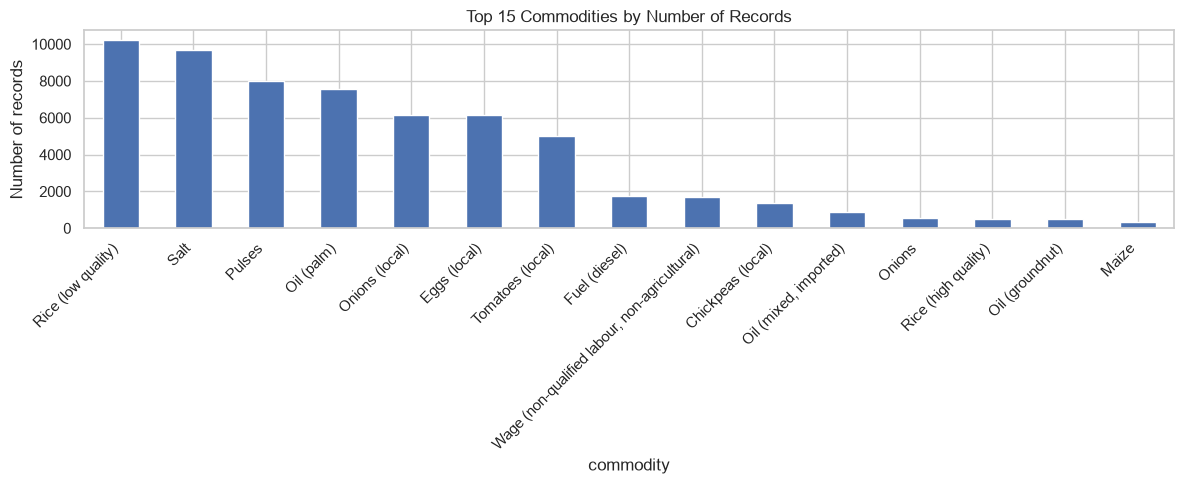

In [12]:
commodity_counts = (
    df["commodity"]
    .value_counts()
    .head(15)
)

commodity_counts.plot(
    kind="bar",
    figsize=(12, 5),
    title="Top 15 Commodities by Number of Records"
)

plt.ylabel("Number of records")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [13]:
TARGET_COMMODITY = "Rice (low quality)"
TARGET_UNIT = "KG"
TARGET_PRICE_TYPE = "Retail"
TARGET_CURRENCY = "MMK"

In [14]:
rice = df[
    (df["commodity"] == TARGET_COMMODITY) &
    (df["unit"] == TARGET_UNIT) &
    (df["pricetype"] == TARGET_PRICE_TYPE) &
    (df["currency"] == TARGET_CURRENCY)
].copy()

rice = rice.dropna(subset=["date"])

print(f"Rice records: {len(rice):,}")
display(rice.head())

Rice records: 10,231


,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice
0,2008-01-15,Kachin,Myitkyina,Wai Maw,1021,25.34,97.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,400.00,0.41
7,2008-01-15,Magway,Magway,Magway,997,20.15,94.92,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,604.17,0.62
10,2008-01-15,Magway,Magway,Yenanchaung,1023,20.46,94.87,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,900.00,0.93
12,2008-01-15,Magway,Pakokku,Pakhangyi,1011,21.54,95.20,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,541.67,0.56
14,2008-01-15,Rakhine,Maungdaw,Alel Than Kyaw,977,20.68,92.44,cereals and tubers,Rice (low quality),145,KG,actual,Retail,MMK,460.00,0.47


In [15]:
rice["month"] = rice["date"].dt.to_period("M")

rice_monthly = (
    rice.groupby(["market_id", "market", "month"])
    .agg(
        monthly_price=("price", "mean"),
        observations=("price", "count")
    )
    .reset_index()
    .sort_values(["market_id", "month"])
)

display(rice_monthly.head())

,market_id,market,month,monthly_price,observations
0,977,Alel Than Kyaw,2008-01,460.0,1
1,977,Alel Than Kyaw,2008-02,450.0,1
2,977,Alel Than Kyaw,2008-03,440.0,1
3,977,Alel Than Kyaw,2008-04,480.0,1
4,977,Alel Than Kyaw,2008-05,480.0,1


In [25]:
PAKOKKU_ID = 1664
LASHIO_ID = 1658
MAGGWAY = 997
SHWEGU = 1657
pakokku = (
    rice_monthly[
        rice_monthly["market_id"] == PAKOKKU_ID
    ]
    .sort_values("month")
    .copy()
)

lashio = (
    rice_monthly[
        rice_monthly["market_id"] == LASHIO_ID
    ]
    .sort_values("month")
    .copy()
)

magway = (
    rice_monthly[
        rice_monthly["market_id"] == MAGGWAY
    ]
    .sort_values("month")
    .copy()
)

shwegu = (
    rice_monthly[
        rice_monthly["market_id"] == SHWEGU
    ]
    .sort_values("month")
    .copy()
)




print("Recorded months:", len(pakokku))

display(pakokku.head())

PeriodIndex(['2008-01', '2008-02', '2008-03', '2008-04', '2008-05', '2008-06',
             '2008-07', '2008-08', '2008-09', '2008-10',
             ...
             '2025-12', '2026-01', '2026-02', '2026-03', '2026-04', '2026-05',
             '2026-06', '2026-07', '2026-08', '2026-09'],
            dtype='period[M]', length=225)

Recorded months: 146


,market_id,market,month,monthly_price,observations
4360,1664,Pakokku Myo Ma Market,2014-01,693.0,1
4361,1664,Pakokku Myo Ma Market,2014-02,693.0,1
4362,1664,Pakokku Myo Ma Market,2014-03,693.0,1
4363,1664,Pakokku Myo Ma Market,2014-04,712.0,1
4364,1664,Pakokku Myo Ma Market,2014-05,708.0,1


In [27]:
for market in [pakokku, lashio, magway, shwegu]:
    start_month = pakokku["month"].min()
    end_month = pakokku["month"].max()

    full_months = pd.period_range(
        start=start_month,
        end=end_month,
        freq="M"
    )

    observed_months = pd.PeriodIndex(pakokku["month"])

    missing_months = full_months.difference(observed_months)
    print(f"Market: {market['market'].iloc[0]}")
    print("Total months:", len(full_months))
    print("Observed months:", len(observed_months))
    print("Missing months:", len(missing_months))

    display(missing_months.to_frame(index=False, name="missing_month"))



Market: Pakokku Myo Ma Market
Total months: 153
Observed months: 146
Missing months: 7


,missing_month
0,2015-05
1,2015-06
2,2015-07
3,2019-05
4,2019-06
5,2020-02
6,2025-01


Market: Lashio Market
Total months: 153
Observed months: 146
Missing months: 7


,missing_month
0,2015-05
1,2015-06
2,2015-07
3,2019-05
4,2019-06
5,2020-02
6,2025-01


Market: Magway
Total months: 153
Observed months: 146
Missing months: 7


,missing_month
0,2015-05
1,2015-06
2,2015-07
3,2019-05
4,2019-06
5,2020-02
6,2025-01


Market: Shwegu
Total months: 153
Observed months: 146
Missing months: 7


,missing_month
0,2015-05
1,2015-06
2,2015-07
3,2019-05
4,2019-06
5,2020-02
6,2025-01


In [30]:
pakokku_ts = (
    pakokku
    .set_index("month")
    .reindex(full_months)
)
print("Pakokku time series shape:", pakokku_ts.shape)
pakokku_ts.index.name = "month"

display(pakokku_ts.head(15))

lashio_ts = (
    lashio
    .set_index("month")
    .reindex(full_months)
)
print("Lashio time series shape:", lashio_ts.shape)

lashio_ts.index.name = "month"
display(lashio_ts.head(15))


magway_ts = (
    magway
    .set_index("month")
    .reindex(full_months)
)
print("Magway time series shape:", magway_ts.shape)

magway_ts.index.name = "month"
display(magway_ts.head(15))


shwegu_ts = (
    shwegu
    .set_index("month")
    .reindex(full_months)
) 
print("Shwegu time series shape:", shwegu_ts.shape)
shwegu_ts.index.name = "month"
display(shwegu_ts.head(15))


Pakokku time series shape: (153, 4)


,market_id,market,monthly_price,observations
month,,,,
2014-01,1664.0,Pakokku Myo Ma Market,693.0,1.0
2014-02,1664.0,Pakokku Myo Ma Market,693.0,1.0
2014-03,1664.0,Pakokku Myo Ma Market,693.0,1.0
2014-04,1664.0,Pakokku Myo Ma Market,712.0,1.0
2014-05,1664.0,Pakokku Myo Ma Market,708.0,1.0
2014-06,1664.0,Pakokku Myo Ma Market,708.0,1.0
2014-07,1664.0,Pakokku Myo Ma Market,708.0,1.0
2014-08,1664.0,Pakokku Myo Ma Market,708.0,1.0
2014-09,1664.0,Pakokku Myo Ma Market,755.0,1.0


Lashio time series shape: (153, 4)


,market_id,market,monthly_price,observations
month,,,,
2014-01,1658.0,Lashio Market,431.0,1.0
2014-02,1658.0,Lashio Market,460.0,1.0
2014-03,1658.0,Lashio Market,376.0,1.0
2014-04,NaN,NaN,NaN,NaN
2014-05,1658.0,Lashio Market,411.0,1.0
2014-06,1658.0,Lashio Market,423.0,1.0
2014-07,NaN,NaN,NaN,NaN
2014-08,1658.0,Lashio Market,506.0,1.0
2014-09,1658.0,Lashio Market,483.0,1.0


Magway time series shape: (153, 4)


,market_id,market,monthly_price,observations
month,,,,
2014-01,997.0,Magway,519.0,1.0
2014-02,997.0,Magway,519.0,1.0
2014-03,997.0,Magway,472.0,1.0
2014-04,997.0,Magway,425.0,1.0
2014-05,997.0,Magway,519.0,1.0
2014-06,997.0,Magway,519.0,1.0
2014-07,997.0,Magway,472.0,1.0
2014-08,997.0,Magway,519.0,1.0
2014-09,997.0,Magway,519.0,1.0


Shwegu time series shape: (153, 4)


,market_id,market,monthly_price,observations
month,,,,
2014-01,1657.0,Shwegu,470.0,1.0
2014-02,1657.0,Shwegu,470.0,1.0
2014-03,1657.0,Shwegu,470.0,1.0
2014-04,1657.0,Shwegu,470.0,1.0
2014-05,1657.0,Shwegu,564.0,1.0
2014-06,1657.0,Shwegu,470.0,1.0
2014-07,1657.0,Shwegu,517.0,1.0
2014-08,1657.0,Shwegu,564.0,1.0
2014-09,1657.0,Shwegu,611.0,1.0


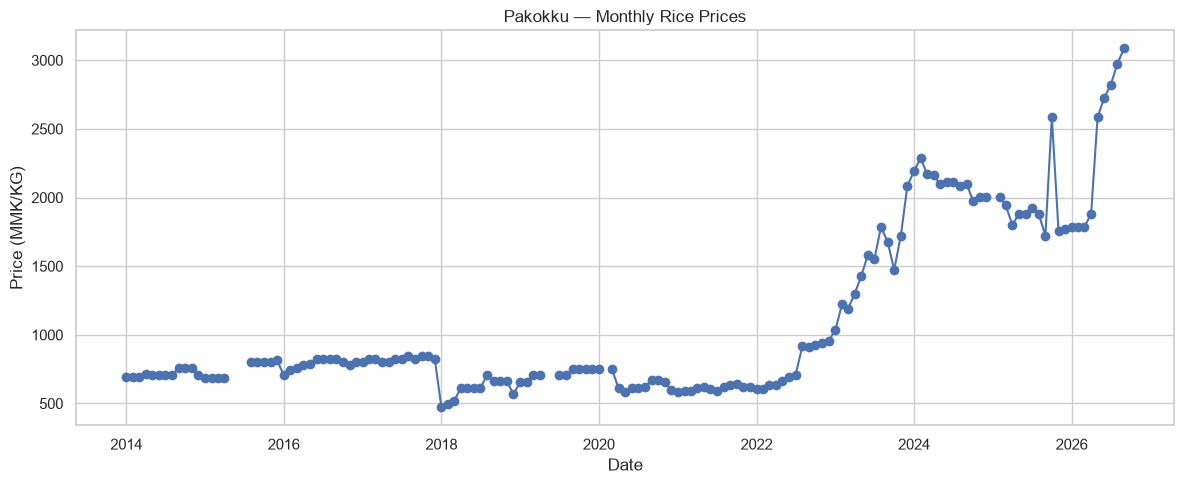

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    pakokku_ts.index.to_timestamp(),
    pakokku_ts["monthly_price"],
    marker="o"
)

plt.title("Pakokku — Monthly Rice Prices")
plt.xlabel("Date")
plt.ylabel("Price (MMK/KG)")

plt.tight_layout()
plt.show()

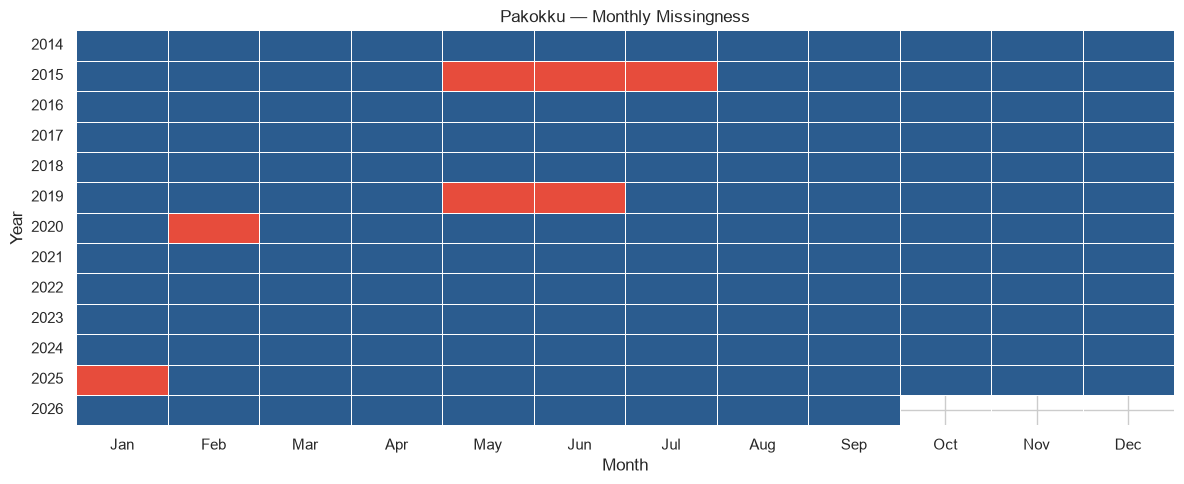

In [20]:
missing_by_year = (
    pakokku_ts
    .assign(
        year=lambda x: x.index.year,
        month=lambda x: x.index.month,
        is_missing=lambda x: x["monthly_price"].isna()
    )
    .pivot(
        index="year",
        columns="month",
        values="is_missing"
    )
)

missing_by_year.columns = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(12, 5))

sns.heatmap(
    missing_by_year.astype(float),
    cmap=["#2b5c8f", "#e74c3c"],
    linewidths=0.5,
    cbar=False
)

plt.title("Pakokku — Monthly Missingness")
plt.xlabel("Month")
plt.ylabel("Year")

plt.tight_layout()
plt.show()

In [21]:
market_coverage = (
    rice_monthly
    .groupby(["market_id", "market"])
    .agg(
        first_month=("month", "min"),
        last_month=("month", "max"),
        observed_months=("month", "nunique")
    )
    .reset_index()
)

market_coverage["expected_months"] = (
    market_coverage["last_month"].map(lambda x: x.ordinal)
    - market_coverage["first_month"].map(lambda x: x.ordinal)
    + 1
)

market_coverage["missing_months"] = (
    market_coverage["expected_months"]
    - market_coverage["observed_months"]
)

market_coverage["missing_percentage"] = (
    market_coverage["missing_months"]
    / market_coverage["expected_months"]
    * 100
).round(2)

market_coverage = market_coverage.sort_values(
    "missing_percentage",
    ascending=False
)

display(market_coverage.head(10))

,market_id,market,first_month,last_month,observed_months,expected_months,missing_months,missing_percentage
210,7929,Kan Htaunt Camp,2022-09,2025-12,2,40,38,95.00
245,10086,Pin Khun,2024-06,2026-09,2,28,26,92.86
147,3342,Barsara,2020-05,2023-03,3,35,32,91.43
55,1377,Shwe Yin Sae,2012-01,2021-01,10,109,99,90.83
53,1375,Nam Hpat Kar,2012-01,2022-03,13,123,110,89.43
61,1399,Ramsi,2012-01,2025-03,18,159,141,88.68
31,1009,Nga Khu Ra,2009-03,2025-11,24,201,177,88.06
18,996,Lungngo,2010-06,2025-02,23,177,154,87.01
156,3351,Waingmaw,2020-05,2025-08,9,64,55,85.94
185,6373,Kyone Doe,2021-12,2023-01,2,14,12,85.71


In [22]:
# Identify consecutive missing periods

is_missing = pakokku_ts["monthly_price"].isna()

missing_groups = (
    is_missing.ne(is_missing.shift()).cumsum()
)

gap_summary = (
    pakokku_ts[is_missing]
    .groupby(missing_groups[is_missing])
    .agg(
        gap_start=("monthly_price", lambda x: x.index.min()),
        gap_end=("monthly_price", lambda x: x.index.max()),
        missing_months=("monthly_price", "size")
    )
    .reset_index(drop=True)
)

display(gap_summary)

,gap_start,gap_end,missing_months
0,2015-05,2015-07,3
1,2019-05,2019-06,2
2,2020-02,2020-02,1
3,2025-01,2025-01,1


In [38]:
# Missingness by calendar month

missing_by_month = (
    pakokku_ts
    .assign(
        calendar_month=lambda x: x.index.month,
        is_missing=lambda x: x["monthly_price"].isna()
    )
    .groupby("calendar_month")["is_missing"]
    .agg(["sum", "mean"])
)

missing_by_month["missing_percentage"] = (
    missing_by_month["mean"] * 100
).round(2)

display(missing_by_month)

,sum,mean,missing_percentage
calendar_month,,,
1,1,0.076923,7.69
2,1,0.076923,7.69
3,0,0.000000,0.00
4,0,0.000000,0.00
5,2,0.153846,15.38
6,2,0.153846,15.38
7,1,0.076923,7.69
8,0,0.000000,0.00
9,0,0.000000,0.00


## IS our dataset MCAR???

**H1** For example, if Pakokku has no observation in May 2019, do other markets also have no observation in May 2019?

In [42]:
# Rows = months, columns = market IDs
price_matrix = (
    rice_monthly
    .pivot(
        index="month",
        columns="market_id",
        values="monthly_price"
    )
    .sort_index()
)

# Complete monthly timeline
all_months = pd.period_range(
    price_matrix.index.min(),
    price_matrix.index.max(),
    freq="M"
)

price_matrix = price_matrix.reindex(all_months)
price_matrix.index.name = "month"

**H2**

In [43]:
first_observed = price_matrix.apply(
    lambda col: col.first_valid_index()
)

last_observed = price_matrix.apply(
    lambda col: col.last_valid_index()
)

active_mask = pd.DataFrame(
    False,
    index=price_matrix.index,
    columns=price_matrix.columns
)

for market_id in price_matrix.columns:
    active_mask[market_id] = (
        (price_matrix.index >= first_observed[market_id]) &
        (price_matrix.index <= last_observed[market_id])
    )

In [44]:
# Missing observations within active reporting periods
internal_missing = price_matrix.isna() & active_mask

# Months outside active reporting periods
structural_missing = ~active_mask

In [45]:
monthly_coverage = pd.DataFrame({
    "active_markets": active_mask.sum(axis=1),
    "missing_markets": internal_missing.sum(axis=1)
})

monthly_coverage["observed_markets"] = (
    monthly_coverage["active_markets"]
    - monthly_coverage["missing_markets"]
)

monthly_coverage["missing_percentage"] = (
    monthly_coverage["missing_markets"]
    / monthly_coverage["active_markets"]
    * 100
).round(2)

display(
    monthly_coverage
    .sort_values("missing_percentage", ascending=False)
    .head(20)
)

,active_markets,missing_markets,observed_markets,missing_percentage
month,,,,
2013-06,36,36,0,100.00
2025-01,147,147,0,100.00
2019-05,41,41,0,100.00
2012-09,53,50,3,94.34
2012-08,53,48,5,90.57
2018-08,41,32,9,78.05
2018-10,41,32,9,78.05
2018-07,41,32,9,78.05
2019-06,41,32,9,78.05


In [46]:
PAKOKKU_ID = 1664

pakokku_missing_months = internal_missing.index[
    internal_missing[PAKOKKU_ID]
]

print("Pakokku missing months:")

display(
    pakokku_missing_months.to_frame(
        index=False,
        name="missing_month"
    )
)

Pakokku missing months:


,missing_month
0,2015-05
1,2015-06
2,2015-07
3,2019-05
4,2019-06
5,2020-02
6,2025-01


In [47]:
pakokku_comparison = pd.DataFrame({
    "missing_markets": internal_missing.loc[
        pakokku_missing_months
    ].sum(axis=1),

    "active_markets": active_mask.loc[
        pakokku_missing_months
    ].sum(axis=1)
})

pakokku_comparison["missing_percentage"] = (
    pakokku_comparison["missing_markets"]
    / pakokku_comparison["active_markets"]
    * 100
).round(2)

display(pakokku_comparison)

,missing_markets,active_markets,missing_percentage
month,,,
2015-05,24,51,47.06
2015-06,23,51,45.10
2015-07,24,51,47.06
2019-05,41,41,100.00
2019-06,32,41,78.05
2020-02,30,41,73.17
2025-01,147,147,100.00


Are missing observations concentrated in particular months or years?



Are multiple active markets missing observations simultaneously?



Does Pakokku exhibit the same missingness patterns as other markets?



Is there evidence of a shared reporting or collection issue?



Which missing observations are reasonable candidates for imputation?

,active_market_months,missing_market_months,missing_percentage
month,,,
2019,492,366,74.39
2018,498,342,68.67
2013,450,224,49.78
2017,537,260,48.42
2025,1409,673,47.76
2016,590,254,43.05
2012,638,264,41.38
2015,612,231,37.75
2024,1748,656,37.53


,active_market_months,missing_market_months,missing_percentage
calendar_month,,,
1,1351,568,42.04
2,1335,428,32.06
3,1317,491,37.28
4,1349,496,36.77
5,1359,514,37.82
6,1370,515,37.59
7,1386,502,36.22
8,1388,503,36.24
9,1386,488,35.21


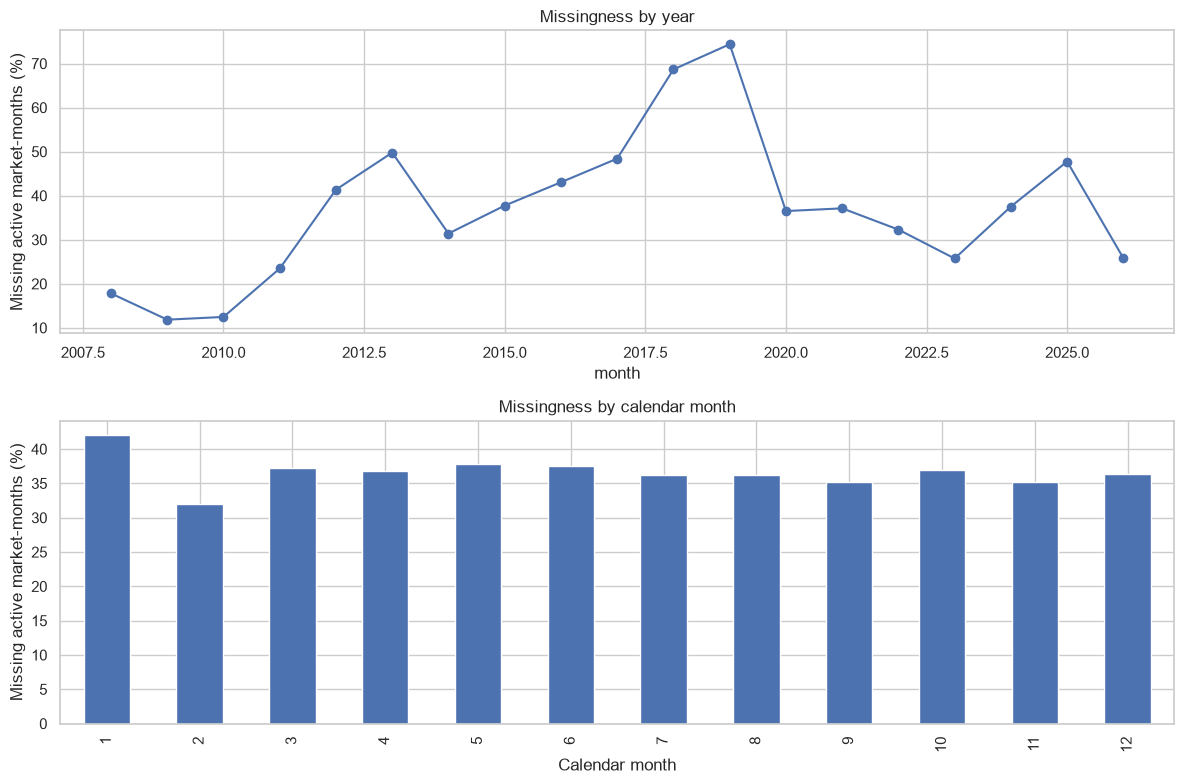

,active_markets,missing_markets,missing_percentage
month,,,
2025-01,147,147,100.000000
2024-01,143,62,43.356643
2024-11,147,62,42.176871
2024-09,147,61,41.496599
2024-07,144,60,41.666667
2024-10,146,59,40.410959
2025-04,110,58,52.727273
2025-05,107,58,54.205607
2025-03,117,57,48.717949


Months with at least 25% of active markets missing: 172
Months with at least 50% of active markets missing: 46
Mean peer missing rate in Pakokku gap months: 69.43%
Mean peer missing rate in other Pakokku-active months: 42.15%


,peer_active_markets,peer_missing_markets,peer_missing_percentage
month,,,
2015-05,50,23,46.0
2015-06,50,22,44.0
2015-07,50,23,46.0
2019-05,40,40,100.0
2019-06,40,31,77.5
2020-02,40,29,72.5
2025-01,146,146,100.0


,market_id,gap_start,gap_end,gap_months,bounded_by_prices,peer_observations_in_gap,peer_missing_percentage,candidate_for_review
2,978,2008-10,2008-11,2,True,48,11.11,True
3,978,2009-10,2009-11,2,True,51,8.93,True
12,978,2023-10,2023-10,1,True,114,21.38,True
20,979,2011-05,2011-05,1,True,34,20.93,True
27,981,2011-01,2011-01,1,True,35,16.67,True
32,982,2008-04,2008-04,1,True,20,23.08,True
35,982,2011-01,2011-01,1,True,35,16.67,True
36,983,2011-01,2011-02,2,True,71,15.48,True
74,995,2008-04,2008-04,1,True,20,23.08,True
77,995,2009-07,2009-07,1,True,26,7.14,True


Potential Pakokku candidates:


,market_id,gap_start,gap_end,gap_months,bounded_by_prices,peer_observations_in_gap,peer_missing_percentage,candidate_for_review


In [48]:
# Missingness by year and calendar month (active market-months only)
active_by_year = active_mask.groupby(active_mask.index.year).sum()
missing_by_year = internal_missing.groupby(internal_missing.index.year).sum()

year_summary = pd.DataFrame({
    "active_market_months": active_by_year.sum(axis=1),
    "missing_market_months": missing_by_year.sum(axis=1),
})
year_summary["missing_percentage"] = (
    year_summary["missing_market_months"]
    / year_summary["active_market_months"]
    * 100
).round(2)

active_by_calendar_month = active_mask.groupby(active_mask.index.month).sum()
missing_by_calendar_month = internal_missing.groupby(
    internal_missing.index.month
).sum()

calendar_month_summary = pd.DataFrame({
    "active_market_months": active_by_calendar_month.sum(axis=1),
    "missing_market_months": missing_by_calendar_month.sum(axis=1),
})
calendar_month_summary["missing_percentage"] = (
    calendar_month_summary["missing_market_months"]
    / calendar_month_summary["active_market_months"]
    * 100
).round(2)
calendar_month_summary.index.name = "calendar_month"

display(year_summary.sort_values("missing_percentage", ascending=False))
display(calendar_month_summary)

fig, axes = plt.subplots(2, 1, figsize=(12, 8))
year_summary["missing_percentage"].plot(
    ax=axes[0], marker="o", title="Missingness by year"
)
calendar_month_summary["missing_percentage"].plot(
    ax=axes[1], kind="bar", title="Missingness by calendar month"
)
axes[0].set_ylabel("Missing active market-months (%)")
axes[1].set_ylabel("Missing active market-months (%)")
axes[1].set_xlabel("Calendar month")
plt.tight_layout()
plt.show()


# How often are multiple active markets missing in the same month?
simultaneous = pd.DataFrame(index=price_matrix.index)
simultaneous["active_markets"] = active_mask.sum(axis=1)
simultaneous["missing_markets"] = internal_missing.sum(axis=1)
simultaneous["missing_percentage"] = (
    simultaneous["missing_markets"]
    .div(simultaneous["active_markets"].replace(0, np.nan))
    .mul(100)
)

display(
    simultaneous.sort_values("missing_markets", ascending=False).head(15)
)
print(
    "Months with at least 25% of active markets missing:",
    int((simultaneous["missing_percentage"] >= 25).sum())
)
print(
    "Months with at least 50% of active markets missing:",
    int((simultaneous["missing_percentage"] >= 50).sum())
)


# Compare peer missingness in Pakokku-missing months with its other active months
pakokku_active = active_mask[PAKOKKU_ID]
pakokku_gaps = internal_missing.index[internal_missing[PAKOKKU_ID]]

peer_active_count = (
    active_mask.sum(axis=1) - pakokku_active.astype(int)
)
peer_missing_count = (
    internal_missing.sum(axis=1)
    - internal_missing[PAKOKKU_ID].astype(int)
)

pakokku_comparison = pd.DataFrame({
    "peer_active_markets": peer_active_count.loc[pakokku_gaps],
    "peer_missing_markets": peer_missing_count.loc[pakokku_gaps],
})
pakokku_comparison["peer_missing_percentage"] = (
    pakokku_comparison["peer_missing_markets"]
    .div(pakokku_comparison["peer_active_markets"].replace(0, np.nan))
    .mul(100)
).round(2)

baseline_months = pakokku_active & ~internal_missing[PAKOKKU_ID]
baseline_peer_rate = (
    peer_missing_count[baseline_months]
    .div(peer_active_count[baseline_months].replace(0, np.nan))
    .mean()
    * 100
)

print(f"Mean peer missing rate in Pakokku gap months: "
      f"{pakokku_comparison['peer_missing_percentage'].mean():.2f}%")
print(f"Mean peer missing rate in other Pakokku-active months: "
      f"{baseline_peer_rate:.2f}%")
display(pakokku_comparison)


# Identify short, bounded internal gaps with peer coverage.
# These are candidates for review, not automatic imputations.
candidate_rows = []

for market_id in internal_missing.columns:
    missing_flags = internal_missing[market_id].to_numpy()
    missing_positions = np.flatnonzero(missing_flags)
    if len(missing_positions) == 0:
        continue

    gaps = np.split(
        missing_positions,
        np.where(np.diff(missing_positions) > 1)[0] + 1
    )

    for positions in gaps:
        start_pos, end_pos = positions[0], positions[-1]
        gap_length = len(positions)
        bounded = (
            start_pos > 0
            and end_pos < len(price_matrix) - 1
            and pd.notna(price_matrix.iloc[start_pos - 1][market_id])
            and pd.notna(price_matrix.iloc[end_pos + 1][market_id])
        )

        peer_active = active_mask.iloc[positions].drop(
            columns=market_id
        )
        peer_missing = internal_missing.iloc[positions].drop(
            columns=market_id
        )
        peer_active_total = int(peer_active.to_numpy().sum())
        peer_missing_total = int(peer_missing.to_numpy().sum())
        peer_observed_total = peer_active_total - peer_missing_total
        peer_missing_rate = (
            100 * peer_missing_total / peer_active_total
            if peer_active_total else np.nan
        )

        candidate_rows.append({
            "market_id": market_id,
            "gap_start": price_matrix.index[start_pos],
            "gap_end": price_matrix.index[end_pos],
            "gap_months": gap_length,
            "bounded_by_prices": bounded,
            "peer_observations_in_gap": peer_observed_total,
            "peer_missing_percentage": (
                round(peer_missing_rate, 2)
                if pd.notna(peer_missing_rate) else np.nan
            ),
            "candidate_for_review": (
                gap_length <= 2
                and bounded
                and peer_observed_total >= 5
                and pd.notna(peer_missing_rate)
                and peer_missing_rate < 25
            ),
        })

imputation_review = pd.DataFrame(candidate_rows)

display(
    imputation_review[
        imputation_review["candidate_for_review"]
    ].sort_values(["market_id", "gap_start"])
)

print("Potential Pakokku candidates:")
display(
    imputation_review[
        (imputation_review["market_id"] == PAKOKKU_ID)
        & imputation_review["candidate_for_review"]
    ]
)